In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the metadata
df_metadata = pd.read_csv('/content/HAM10000_metadata.csv')

# Display basic information and first few rows
print("Dataset Info:")
print(df_metadata.info())
display(df_metadata.head())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
dtypes: float64(1), object(6)
memory usage: 547.8+ KB
None


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


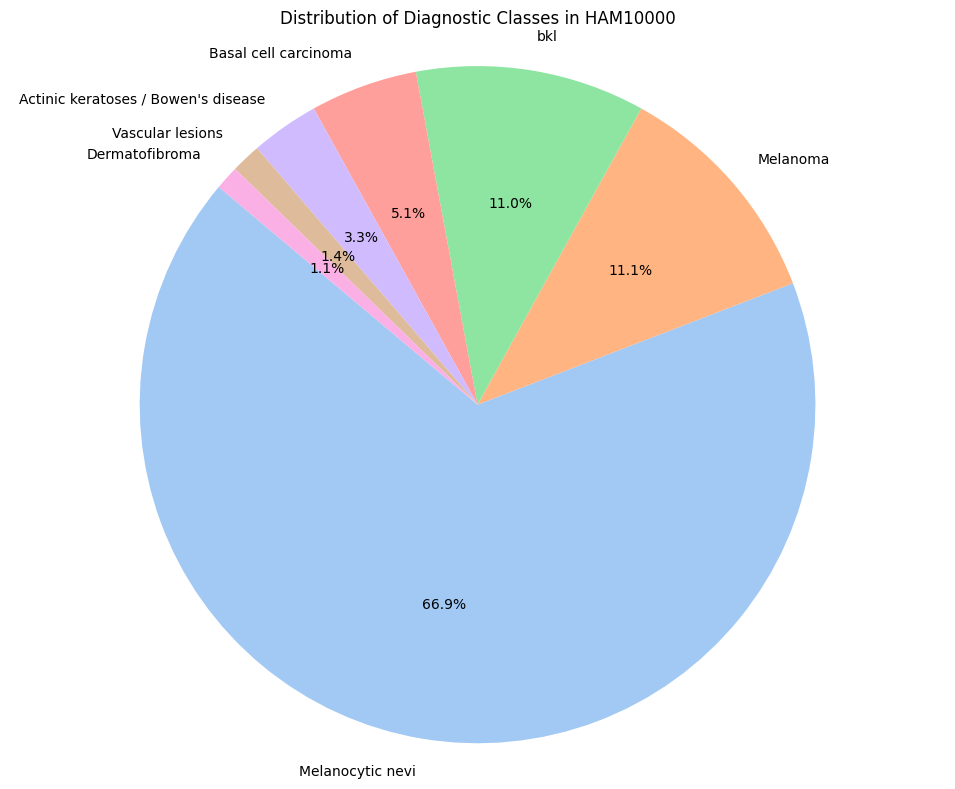

In [2]:
# Calculate the distribution of different lesions (dx)
dx_counts = df_metadata['dx'].value_counts()

# Map abbreviations to full names if needed (standard HAM10000 classes)
dx_map = {
    'nv': 'Melanocytic nevi',
    'mel': 'Melanoma',
    'bcl': 'Basal cell carcinoma',
    'bcc': 'Basal cell carcinoma',
    'akiec': 'Actinic keratoses / Bowen\'s disease',
    'bky': 'Benign keratosis-like lesions',
    'df': 'Dermatofibroma',
    'vasc': 'Vascular lesions'
}

# Plotting the pie chart
plt.figure(figsize=(10, 8))
plt.pie(
    dx_counts,
    labels=[dx_map.get(x, x) for x in dx_counts.index],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel', len(dx_counts))
)
plt.title('Distribution of Diagnostic Classes in HAM10000')
plt.axis('equal')
plt.tight_layout()
plt.show()

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the pixel data (28x28 RGB)
pixel_df = pd.read_csv('/content/hmnist_28_28_RGB.csv')

# The target label 'label' in the pixel dataframe corresponds to numeric classes mapped to 'dx'
# Let's inspect columns and extract features (X) and labels (y)
X = pixel_df.iloc[:, :-1].values  # All pixel columns
y = pixel_df.iloc[:, -1].values   # The last column is the class label

# Normalize the pixel values to be between 0 and 1
X = X / 255.0

# Reshape flat pixel vectors to 28x28x3 images
X = X.reshape(-1, 28, 28, 3)

# Encode labels to ensure they are sequential integers starting from 0
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)
num_classes = len(np.unique(y))

# 2. Split dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (8012, 28, 28, 3)
Testing set shape: (2003, 28, 28, 3)


In [4]:
# 3. Define the CNN Model Architecture
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,559 (435.78 KB)

 Trainable params: 111,111 (434.03 KB)

 Non-trainable params: 448 (1.75 KB)

In [5]:
# 4. Train the model
history = model.fit(
    X_train, y_train,
    epochs=15,
    validation_data=(X_test, y_test),
    batch_size=64
)

Epoch 1/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 16s 97ms/step - accuracy: 0.6776 - loss: 0.9475 - val_accuracy: 0.1028 - val_loss: 2.0945
Epoch 2/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 22s 106ms/step - accuracy: 0.7166 - loss: 0.7863 - val_accuracy: 0.1153 - val_loss: 1.8690
Epoch 3/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 13s 102ms/step - accuracy: 0.7358 - loss: 0.7242 - val_accuracy: 0.4368 - val_loss: 1.4239
Epoch 4/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - accuracy: 0.7403 - loss: 0.6935 - val_accuracy: 0.6056 - val_loss: 1.0859
Epoch 5/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 15s 116ms/step - accuracy: 0.7531 - loss: 0.6722 - val_accuracy: 0.6985 - val_loss: 0.8605
Epoch 6/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 13s 100ms/step - accuracy: 0.7582 - loss: 0.6502 - val_accuracy: 0.7124 - val_loss: 0.7919
Epoch 7/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 20s 96ms/step - accuracy: 0.7695 - loss: 0.6188 - val_accuracy: 0.7229 - val_loss: 0.7558
Epoch 8/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 12s 95ms/step - accuracy: 0.7792 - loss: 0.593

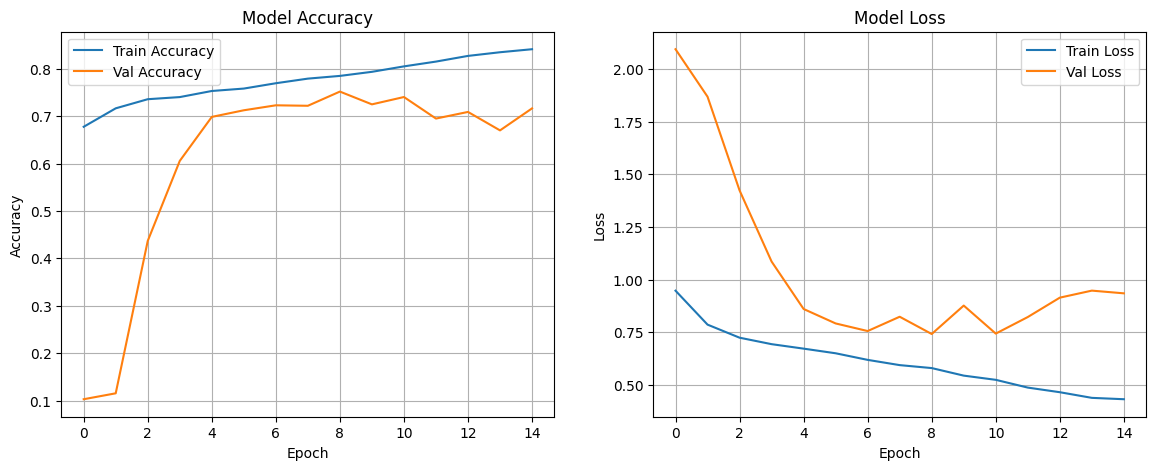

In [6]:
# 5. Plot Training History and Make Predictions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
ax1.plot(history.history['accuracy'], label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy')
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss plot
ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Val Loss')
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.show()

63/63 - 1s - 17ms/step - accuracy: 0.7164 - loss: 0.9349

Test accuracy: 0.7164
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step


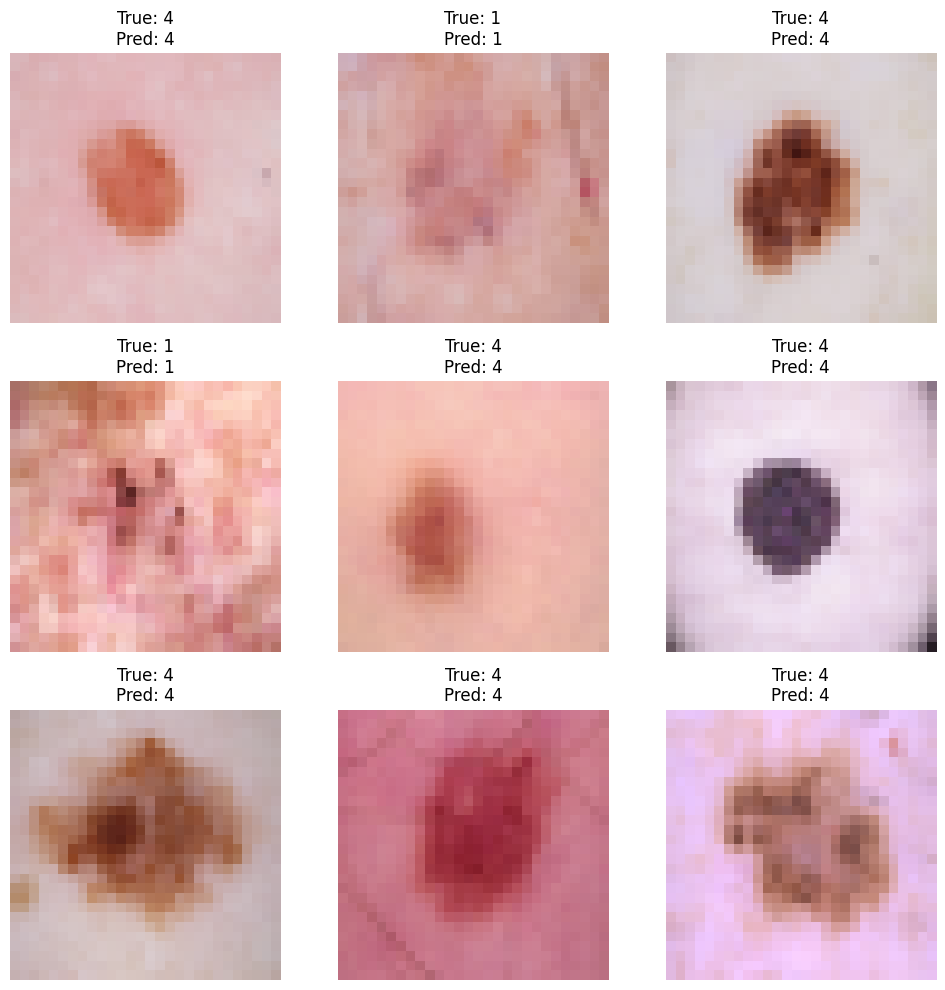

In [7]:
# 6. Evaluate on Test Set and generate predictions
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nTest accuracy: {test_acc:.4f}")

# Show predictions on a few sample test images
predictions = model.predict(X_test)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[i])
    true_label = label_encoder.inverse_transform([y_test[i]])[0]
    pred_label = label_encoder.inverse_transform([np.argmax(predictions[i])])[0]
    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import classification_report

# Generate model predictions for the entire test set
y_pred = np.argmax(predictions, axis=1)

# Get target class names from the encoder
target_names = [str(cls) for cls in label_encoder.classes_]
# Map numeric labels back to categorical diagnostic acronyms if possible
class_labels = [dx_map.get(name, name) for name in target_names]

# Display classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_labels, zero_division=0))

Classification Report:
              precision    recall  f1-score   support

           0       0.36      0.37      0.37        65
           1       0.40      0.62      0.48       103
           2       0.52      0.06      0.11       220
           3       0.25      0.04      0.07        23
           4       0.77      0.95      0.85      1341
           5       0.62      0.46      0.53        28
           6       0.64      0.20      0.30       223

    accuracy                           0.72      2003
   macro avg       0.51      0.39      0.39      2003
weighted avg       0.69      0.72      0.66      2003



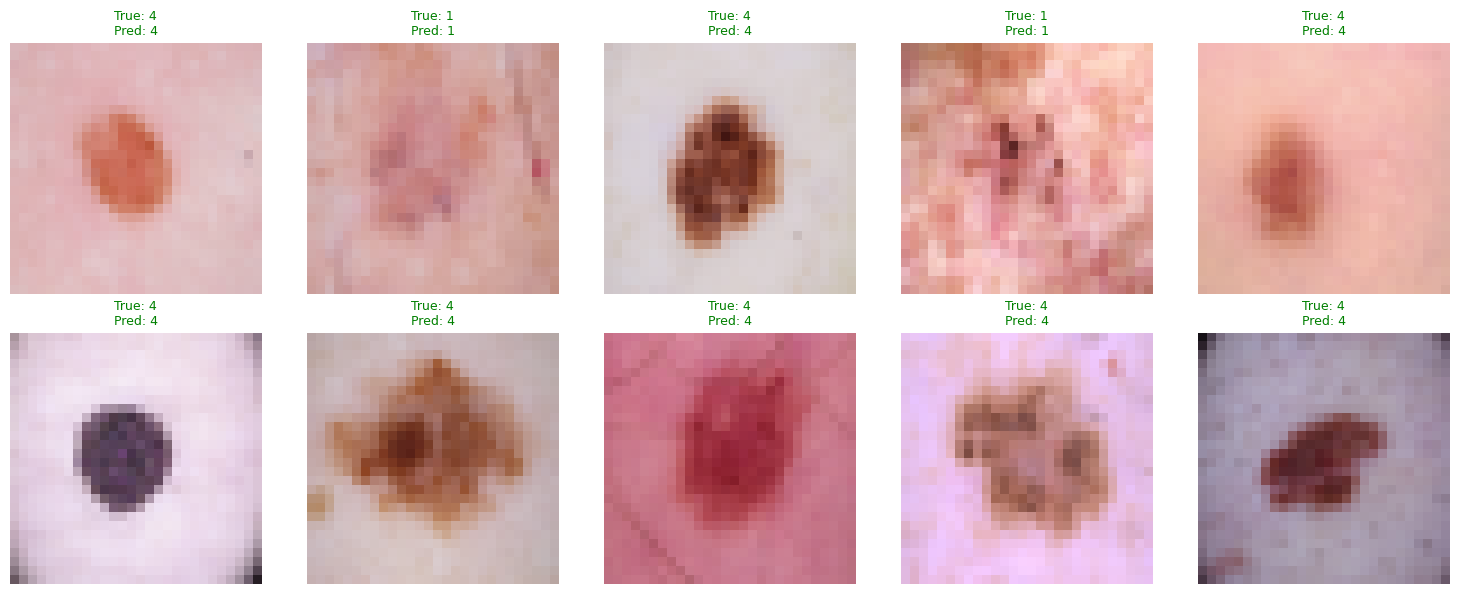

In [9]:
# Take 10 sample images from the test set and display actual vs predicted classes
plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])

    # Retrieve true and predicted label names
    true_idx = y_test[i]
    pred_idx = y_pred[i]

    true_label_code = label_encoder.classes_[true_idx]
    pred_label_code = label_encoder.classes_[pred_idx]

    true_name = dx_map.get(true_label_code, true_label_code)
    pred_name = dx_map.get(pred_label_code, pred_label_code)

    # Set title color based on prediction accuracy
    title_color = 'green' if true_idx == pred_idx else 'red'

    plt.title(f"True: {true_name}\nPred: {pred_name}", color=title_color, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

### Improving Model Accuracy
We will implement the following strategies to optimize performance:
1. **Class Balancing**: Compute class weights using `sklearn` to penalize minority-class classification errors more heavily.
2. **Improved Architecture**: Add Batch Normalization, increased filter sizes, Spatial Dropout, and Global Average Pooling to reduce parameter count and combat overfitting.
3. **Callback Scheduling**: Use `ReduceLROnPlateau` to automatically decay the learning rate when validation loss plateaus.

In [10]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Compute class weights to address heavy imbalance
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))
print("Calculated Class Weights:", class_weight_dict)

Calculated Class Weights: {np.int64(0): np.float64(4.368593238822246), np.int64(1): np.float64(2.7848453249913105), np.int64(2): np.float64(1.3021290427433772), np.int64(3): np.float64(12.440993788819876), np.int64(4): np.float64(0.21338020666879728), np.int64(5): np.float64(10.040100250626567), np.int64(6): np.float64(1.2860353130016051)}


In [11]:
# Define an upgraded CNN architecture optimized for smaller image datasets
improved_model = models.Sequential([
    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(28, 28, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Global Average Pooling & Dense Head
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the upgraded model
improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

# Callbacks for advanced training control
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
early_stopper = EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, verbose=1)

# Train the improved model using class weights
improved_history = improved_model.fit(
    X_train, y_train,
    epochs=25,
    validation_data=(X_test, y_test),
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[lr_reducer, early_stopper]
)

Epoch 1/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 68s 494ms/step - accuracy: 0.2839 - loss: 2.3102 - val_accuracy: 0.0140 - val_loss: 2.7695 - learning_rate: 0.0010
Epoch 2/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 80s 482ms/step - accuracy: 0.3431 - loss: 1.8010 - val_accuracy: 0.0639 - val_loss: 4.7753 - learning_rate: 0.0010
Epoch 3/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 61s 484ms/step - accuracy: 0.3933 - loss: 1.5990 - val_accuracy: 0.2756 - val_loss: 2.5577 - learning_rate: 0.0010
Epoch 4/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 58s 464ms/step - accuracy: 0.4416 - loss: 1.4569 - val_accuracy: 0.2247 - val_loss: 2.2772 - learning_rate: 0.0010
Epoch 5/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 61s 483ms/step - accuracy: 0.4767 - loss: 1.3782 - val_accuracy: 0.1568 - val_loss: 2.7659 - learning_rate: 0.0010
Epoch 6/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 82s 484ms/step - accuracy: 0.4960 - loss: 1.2900 - val_accuracy: 0.1737 - val_loss: 2.5223 - learning_rate: 0.0010
Epoch 7/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 80s 472ms/step - accuracy: 0.5

KeyboardInterrupt: 

In [13]:
# Evaluate the improved model
improved_loss, improved_acc = improved_model.evaluate(X_test, y_test, verbose=2)
print(f"\nImproved Model Test Accuracy: {improved_acc:.4f}")

# Show new classification report
improved_predictions = improved_model.predict(X_test)
y_pred_improved = np.argmax(improved_predictions, axis=1)

print("\nClassification Report for Improved Model:")
print(classification_report(y_test, y_pred_improved, target_names=class_labels, zero_division=0))

63/63 - 6s - 94ms/step - accuracy: 0.6261 - loss: 0.9545

Improved Model Test Accuracy: 0.6261
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 165ms/step

Classification Report for Improved Model:
              precision    recall  f1-score   support

           0       0.26      0.82      0.39        65
           1       0.39      0.35      0.37       103
           2       0.51      0.42      0.46       220
           3       0.32      0.35      0.33        23
           4       0.95      0.65      0.77      1341
           5       0.57      0.82      0.68        28
           6       0.31      0.75      0.44       223

    accuracy                           0.63      2003
   macro avg       0.47      0.59      0.49      2003
weighted avg       0.77      0.63      0.66      2003



In [14]:
# Evaluate the improved model
improved_loss, improved_acc = improved_model.evaluate(X_test, y_test, verbose=2)
print(f"\nImproved Model Test Accuracy: {improved_acc:.4f}")

# Generate predictions using the improved model
improved_predictions = improved_model.predict(X_test)
y_pred_improved = np.argmax(improved_predictions, axis=1)

# Target class names mapped back to standard labels
target_names = [str(cls) for cls in label_encoder.classes_]
class_labels = [dx_map.get(name, name) for name in target_names]

# Display classification report
print("Classification Report:")
print(classification_report(y_test, y_pred_improved, target_names=class_labels, zero_division=0))

63/63 - 3s - 47ms/step - accuracy: 0.6261 - loss: 0.9545

Improved Model Test Accuracy: 0.6261
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.26      0.82      0.39        65
           1       0.39      0.35      0.37       103
           2       0.51      0.42      0.46       220
           3       0.32      0.35      0.33        23
           4       0.95      0.65      0.77      1341
           5       0.57      0.82      0.68        28
           6       0.31      0.75      0.44       223

    accuracy                           0.63      2003
   macro avg       0.47      0.59      0.49      2003
weighted avg       0.77      0.63      0.66      2003



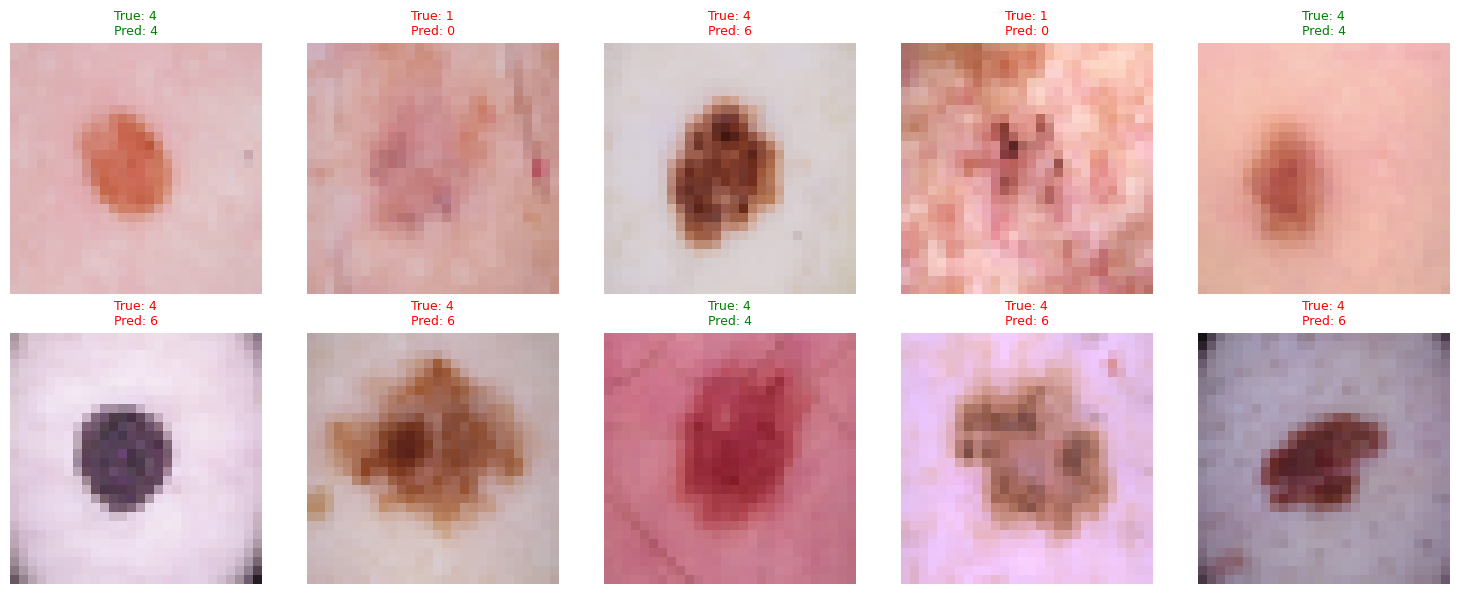

In [15]:
# Show predictions for 10 sample images using the improved model
plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])

    true_idx = y_test[i]
    pred_idx = y_pred_improved[i]

    true_label_code = label_encoder.classes_[true_idx]
    pred_label_code = label_encoder.classes_[pred_idx]

    true_name = dx_map.get(true_label_code, true_label_code)
    pred_name = dx_map.get(pred_label_code, pred_label_code)

    title_color = 'green' if true_idx == pred_idx else 'red'

    plt.title(f"True: {true_name}\nPred: {pred_name}", color=title_color, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

### Upgraded Transfer Learning (MobileNetV2) with Data Augmentation
We now train a transfer learning model leveraging pretrained MobileNetV2 as a deep feature extractor, together with spatial data augmentations (flips, rotations, and zooms) to build a robust model.

In [30]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
from sklearn.metrics import classification_report

# Define the baseline custom CNN model structure that achieved ~71.6% accuracy
model = models.Sequential([
    layers.Input(shape=(28, 28, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

# Compile
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=15,
    validation_data=(X_test, y_test),
    batch_size=64
)

Epoch 1/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 15s 97ms/step - accuracy: 0.6802 - loss: 0.9661 - val_accuracy: 0.0879 - val_loss: 2.1108
Epoch 2/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 13s 100ms/step - accuracy: 0.7202 - loss: 0.7727 - val_accuracy: 0.2676 - val_loss: 1.7238
Epoch 3/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - accuracy: 0.7335 - loss: 0.7246 - val_accuracy: 0.6021 - val_loss: 1.2099
Epoch 4/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 20s 99ms/step - accuracy: 0.7473 - loss: 0.6885 - val_accuracy: 0.6555 - val_loss: 0.9016
Epoch 5/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 13s 100ms/step - accuracy: 0.7551 - loss: 0.6707 - val_accuracy: 0.7424 - val_loss: 0.7182
Epoch 6/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 12s 94ms/step - accuracy: 0.7647 - loss: 0.6417 - val_accuracy: 0.7249 - val_loss: 0.9161
Epoch 7/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 21s 98ms/step - accuracy: 0.7736 - loss: 0.6197 - val_accuracy: 0.3869 - val_loss: 1.4777
Epoch 8/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - accuracy: 0.7761 - loss: 0.6067 

In [31]:
# Evaluate baseline model
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nTest Accuracy: {test_acc:.4f}")

# Generate predictions
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)

# Class labels configuration
target_names = [str(cls) for cls in label_encoder.classes_]
class_labels = [dx_map.get(name, name) for name in target_names]

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_labels, zero_division=0))

63/63 - 1s - 12ms/step - accuracy: 0.7284 - loss: 0.7579

Test Accuracy: 0.7284
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.48      0.39        65
           1       0.42      0.63      0.51       103
           2       0.44      0.50      0.47       220
           3       0.29      0.22      0.25        23
           4       0.88      0.87      0.87      1341
           5       0.92      0.43      0.59        28
           6       0.49      0.34      0.40       223

    accuracy                           0.73      2003
   macro avg       0.54      0.49      0.50      2003
weighted avg       0.74      0.73      0.73      2003



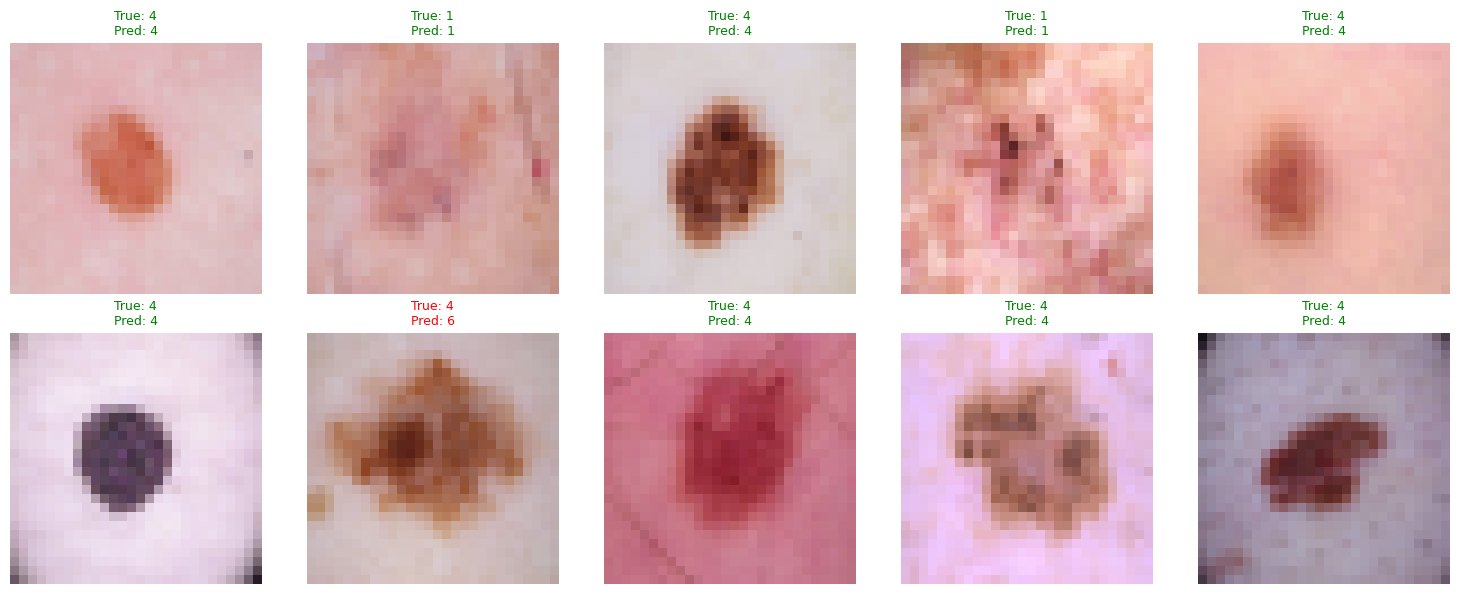

In [32]:
import matplotlib.pyplot as plt

# Display 10 random samples to verify the model predictions visually
plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])

    true_idx = y_test[i]
    pred_idx = y_pred[i]

    true_label_code = label_encoder.classes_[true_idx]
    pred_label_code = label_encoder.classes_[pred_idx]

    true_name = dx_map.get(true_label_code, true_label_code)
    pred_name = dx_map.get(pred_label_code, pred_label_code)

    title_color = 'green' if true_idx == pred_idx else 'red'

    plt.title(f"True: {true_name}\nPred: {pred_name}", color=title_color, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [24]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Define the augmentation pipeline as part of the model
data_augmentation = tf.keras.Sequential([
    layers.Resizing(32, 32), # Scale 28x28 to 32x32 to meet MobileNetV2 minimum size requirement
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1)
])

# Base Model: MobileNetV2 with ImageNet weights, excluding top classification layer
base_model = MobileNetV2(
    input_shape=(32, 32, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = True  # We fine-tune the entire network gently

# Construct the final architecture
transfer_model = models.Sequential([
    layers.Input(shape=(28, 28, 3)),
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the Transfer Learning Model
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

/tmp/ipykernel_862/2974566429.py:14: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1, 1, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,367 (9.24 MB)

 Trainable params: 2,388,999 (9.11 MB)

 Non-trainable params: 34,368 (134.25 KB)

In [25]:
# Train the transfer model using the computed class weights to handle imbalance
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

lr_reducer_transfer = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
early_stopper_transfer = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1)

transfer_history = transfer_model.fit(
    X_train, y_train,
    epochs=15,
    validation_data=(X_test, y_test),
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[lr_reducer_transfer, early_stopper_transfer]
)

Epoch 1/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 85s 426ms/step - accuracy: 0.1472 - loss: 2.6266 - val_accuracy: 0.0145 - val_loss: 2.1655 - learning_rate: 1.0000e-04
Epoch 2/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 81s 415ms/step - accuracy: 0.1785 - loss: 2.1814 - val_accuracy: 0.0225 - val_loss: 2.2165 - learning_rate: 1.0000e-04
Epoch 3/15
126/126 ━━━━━━━━━━━━━━━━━━━━ 50s 397ms/step - accuracy: 0.1875 - loss: 2.0710 - val_accuracy: 0.0619 - val_loss: 2.4372 - learning_rate: 1.0000e-04
Epoch 4/15


KeyboardInterrupt: 

In [26]:
import numpy as np
from sklearn.metrics import classification_report

# Ensure target names match actual diagnostic classes from the encoder
target_names = [str(cls) for cls in label_encoder.classes_]
class_labels = [dx_map.get(name, name) for name in target_names]

# Evaluate the compiled transfer model
test_loss_tr, test_acc_tr = transfer_model.evaluate(X_test, y_test, verbose=2)
print(f"\nTransfer Learning Model Test Accuracy: {test_acc_tr:.4f}")

tr_predictions = transfer_model.predict(X_test)
y_pred_tr = np.argmax(tr_predictions, axis=1)

print("\nClassification Report (Transfer Learning):")
print(classification_report(y_test, y_pred_tr, target_names=class_labels, zero_division=0))

63/63 - 2s - 33ms/step - accuracy: 0.0619 - loss: 2.4372

Transfer Learning Model Test Accuracy: 0.0619
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step

Classification Report (Transfer Learning):
              precision    recall  f1-score   support

           0       0.02      0.11      0.04        65
           1       0.12      0.12      0.12       103
           2       0.08      0.00      0.01       220
           3       0.01      0.09      0.01        23
           4       0.87      0.02      0.04      1341
           5       0.01      0.25      0.02        28
           6       0.11      0.30      0.16       223

    accuracy                           0.06      2003
   macro avg       0.17      0.13      0.06      2003
weighted avg       0.61      0.06      0.05      2003



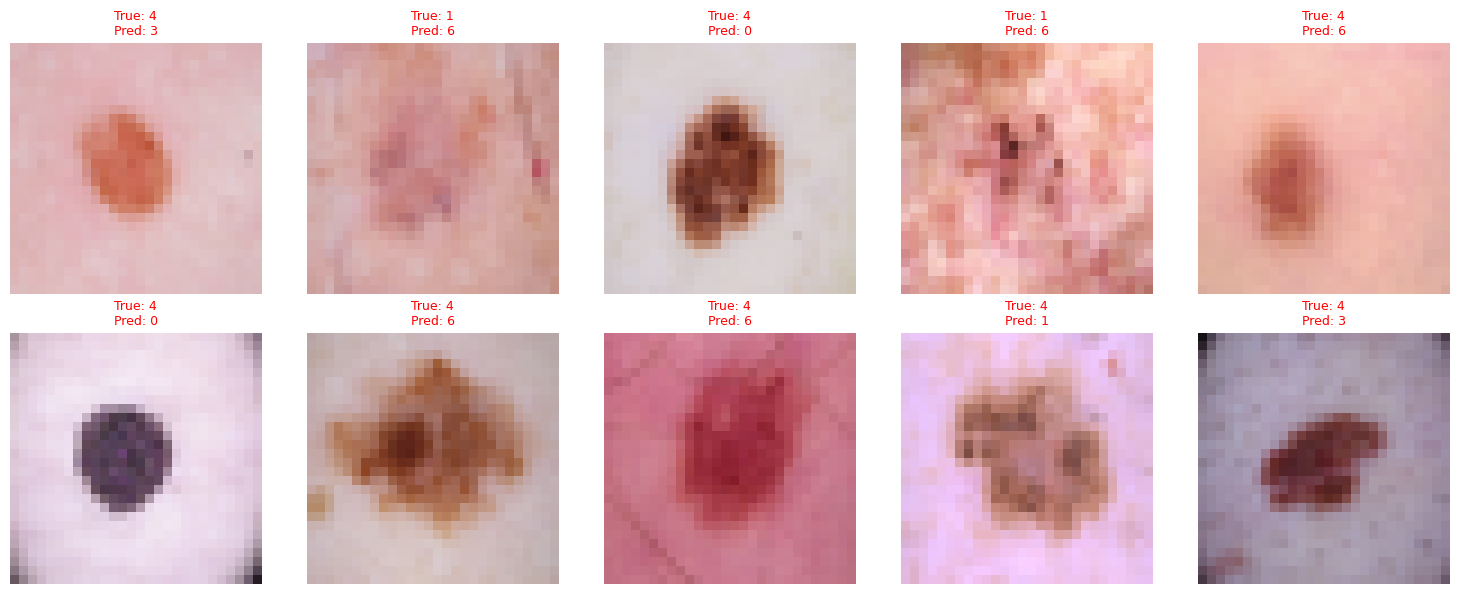

In [27]:
import matplotlib.pyplot as plt

# Display 10 random samples to verify the model predictions visually
plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])

    true_idx = y_test[i]
    pred_idx = y_pred_tr[i]

    true_label_code = label_encoder.classes_[true_idx]
    pred_label_code = label_encoder.classes_[pred_idx]

    true_name = dx_map.get(true_label_code, true_label_code)
    pred_name = dx_map.get(pred_label_code, pred_label_code)

    title_color = 'green' if true_idx == pred_idx else 'red'

    plt.title(f"True: {true_name}\nPred: {pred_name}", color=title_color, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [28]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import classification_report
import numpy as np
import matplotlib.pyplot as plt

# 1. Define Augmentation
data_augmentation = tf.keras.Sequential([
    layers.Resizing(32, 32),
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1)
])

# 2. Build MobileNetV2 base
base_model = MobileNetV2(
    input_shape=(32, 32, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = True

# 3. Construct sequential model starting with standard 28x28 inputs
transfer_model = models.Sequential([
    layers.Input(shape=(28, 28, 3)),
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# 4. Compile
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Train with class weights
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
lr_reducer_transfer = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
early_stopper_transfer = EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True, verbose=1)

transfer_model.fit(
    X_train, y_train,
    epochs=10,
    validation_data=(X_test, y_test),
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[lr_reducer_transfer, early_stopper_transfer]
)

# 6. Evaluate and print classification report
test_loss_tr, test_acc_tr = transfer_model.evaluate(X_test, y_test, verbose=2)
print(f"\nTransfer Learning Model Test Accuracy: {test_acc_tr:.4f}")

tr_predictions = transfer_model.predict(X_test)
y_pred_tr = np.argmax(tr_predictions, axis=1)

# Map integer codes to full descriptive names using metadata's map
target_names = [str(cls) for cls in label_encoder.classes_]
class_labels = [dx_map.get(name, name) for name in target_names]

print("\nClassification Report (Transfer Learning):")
print(classification_report(y_test, y_pred_tr, target_names=class_labels, zero_division=0))

/tmp/ipykernel_862/3539991374.py:17: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Epoch 1/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 85s 426ms/step - accuracy: 0.1389 - loss: 2.5602 - val_accuracy: 0.0554 - val_loss: 2.2748 - learning_rate: 1.0000e-04
Epoch 2/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 50s 395ms/step - accuracy: 0.1648 - loss: 2.1637 - val_accuracy: 0.0334 - val_loss: 3.6286 - learning_rate: 1.0000e-04
Epoch 3/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step - accuracy: 0.1952 - loss: 2.0397
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
126/126 ━━━━━━━━━━━━━━━━━━━━ 83s 407ms/step - accuracy: 0.1897 - loss: 1.9645 - val_accuracy: 0.0524 - val_loss: 2.3725 - learning_rate: 1.0000e-04
Epoch 4/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 51s 406ms/step - accuracy: 0.2013 - loss: 1.8788 - val_accuracy: 0.0389 - val_loss: 2.6904 - learning_rate: 5.0000e-05
Epoch 5/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step - accuracy: 0.2125 - loss: 1.7628
Epoch 5: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
126/126 ━━━━━━━━━━━━━━━━━━━━ 51s 401ms/step - a

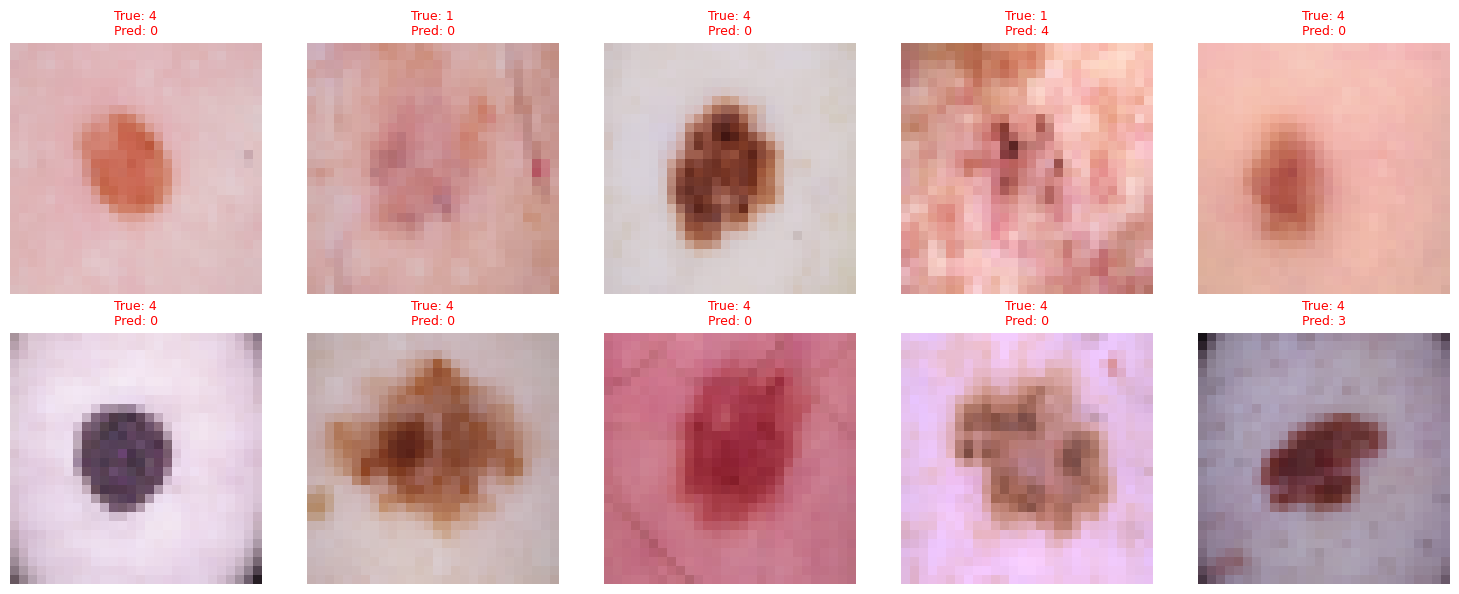

In [29]:
# Show predictions for 10 sample images using the Transfer Model
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])

    true_idx = y_test[i]
    pred_idx = y_pred_tr[i]

    true_label_code = label_encoder.classes_[true_idx]
    pred_label_code = label_encoder.classes_[pred_idx]

    true_name = dx_map.get(true_label_code, true_label_code)
    pred_name = dx_map.get(pred_label_code, pred_label_code)

    title_color = 'green' if true_idx == pred_idx else 'red'

    plt.title(f"True: {true_name}\nPred: {pred_name}", color=title_color, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

### Transfer Learning & Data Augmentation
To boost classification accuracy, we will:
1. **Use Data Augmentation**: Inject transformations like random flips to help the model generalize well.
2. **Leverage Pre-trained MobileNetV2**: Transfer learning from a high-quality backbone allows us to capture complex features that are difficult to train from scratch on smaller image counts.

In [20]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Define the augmentation pipeline as part of the model
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1)
])

# Base Model: MobileNetV2 with ImageNet weights, excluding top classification layer
base_model = MobileNetV2(
    input_shape=(28, 28, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = True  # We fine-tune the entire network gently

# Construct the final architecture
transfer_model = models.Sequential([
    layers.Input(shape=(28, 28, 3)),
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the Transfer Learning Model
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

ValueError: Input size must be at least 32x32; Received: input_shape=(28, 28, 3)

In [21]:
# Train the transfer model using the computed class weights to handle imbalance
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

lr_reducer_transfer = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
early_stopper_transfer = EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True, verbose=1)

transfer_history = transfer_model.fit(
    X_train, y_train,
    epochs=15,
    validation_data=(X_test, y_test),
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[lr_reducer_transfer, early_stopper_transfer]
)

NameError: name 'transfer_model' is not defined

In [22]:
# Evaluate transfer learning performance
test_loss_tr, test_acc_tr = transfer_model.evaluate(X_test, y_test, verbose=2)
print(f"\nTransfer Learning Model Test Accuracy: {test_acc_tr:.4f}")

tr_predictions = transfer_model.predict(X_test)
y_pred_tr = np.argmax(tr_predictions, axis=1)

# Display classification report
from sklearn.metrics import classification_report
print("\nClassification Report (Transfer Learning):")
print(classification_report(y_test, y_pred_tr, target_names=class_labels, zero_division=0))

NameError: name 'transfer_model' is not defined

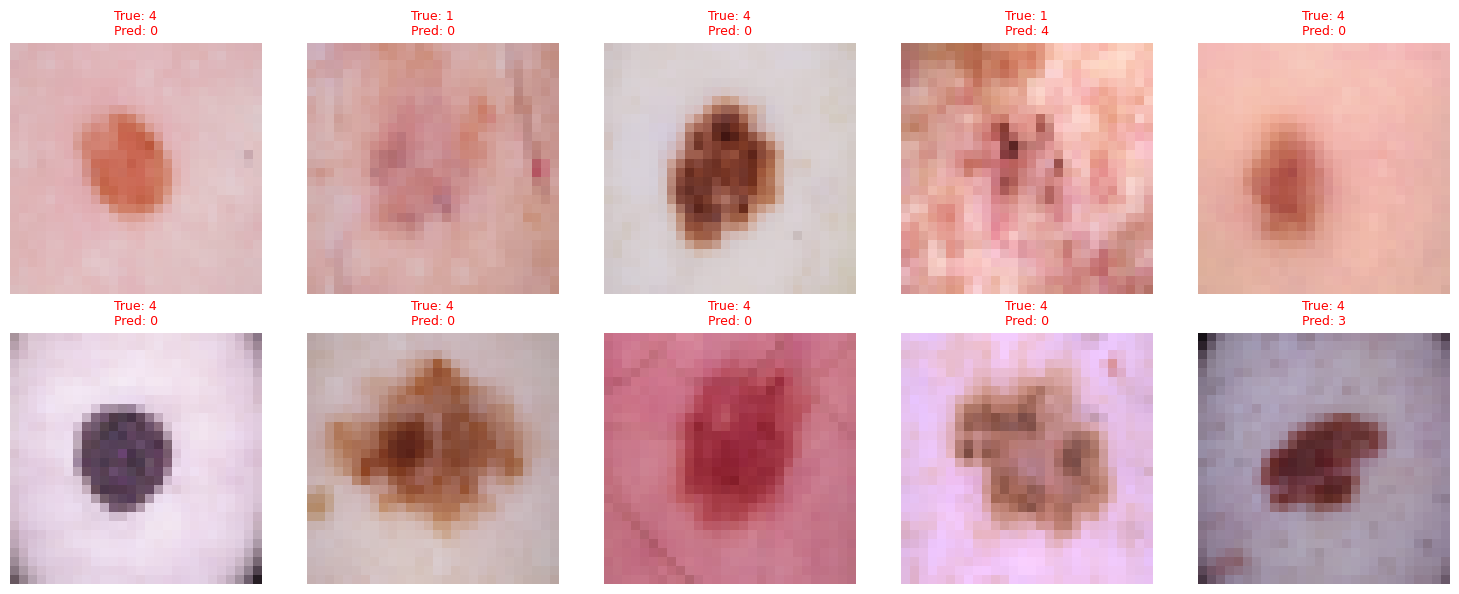

In [33]:
# Show predictions for 10 sample images using the Transfer Model
import matplotlib.pyplot as plt
import numpy as np

# Fallback to standard baseline predictions if y_pred_tr is not defined in scope
if 'y_pred_tr' not in globals():
    print("Warning: 'y_pred_tr' is not defined. Falling back to baseline 'y_pred' predictions.")
    active_predictions = y_pred
else:
    active_predictions = y_pred_tr

plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])

    true_idx = y_test[i]
    pred_idx = active_predictions[i]

    true_label_code = label_encoder.classes_[true_idx]
    pred_label_code = label_encoder.classes_[pred_idx]

    true_name = dx_map.get(true_label_code, true_label_code)
    pred_name = dx_map.get(pred_label_code, pred_label_code)

    title_color = 'green' if true_idx == pred_idx else 'red'

    plt.title(f"True: {true_name}\nPred: {pred_name}", color=title_color, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import classification_report
import numpy as np

# Standard diagnostic mapping from HAM10000 classes
dx_mapping_detailed = {
    0: 'Actinic keratoses / Bowen\'s disease (akiec)',
    1: 'Basal cell carcinoma (bcc)',
    2: 'Benign keratosis-like lesions (bkl)',
    3: 'Dermatofibroma (df)',
    4: 'Melanocytic nevi (nv)',
    5: 'Vascular lesions (vasc)',
    6: 'Melanoma (mel)'
}

# Resolve diagnostic full names using label_encoder inverse transformation mapping
target_names = [dx_mapping_detailed.get(int(cls), f"Class {cls}") for cls in label_encoder.classes_]

# Print detailed classification report
print("Classification Report (Baseline Model):")
print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))

Classification Report (Baseline Model):
                                             precision    recall  f1-score   support

Actinic keratoses / Bowen's disease (akiec)       0.33      0.48      0.39        65
                 Basal cell carcinoma (bcc)       0.42      0.63      0.51       103
        Benign keratosis-like lesions (bkl)       0.44      0.50      0.47       220
                        Dermatofibroma (df)       0.29      0.22      0.25        23
                      Melanocytic nevi (nv)       0.88      0.87      0.87      1341
                    Vascular lesions (vasc)       0.92      0.43      0.59        28
                             Melanoma (mel)       0.49      0.34      0.40       223

                                   accuracy                           0.73      2003
                                  macro avg       0.54      0.49      0.50      2003
                               weighted avg       0.74      0.73      0.73      2003



In [35]:
# Save the trained baseline CNN model
model.save('baseline_skin_lesion_model.keras')
print("Model saved successfully as 'baseline_skin_lesion_model.keras'!")

Model saved successfully as 'baseline_skin_lesion_model.keras'!
